C3S CORDEX - Remapping with clisops + xESMF
===========================================

In an extensive test of remapping C3S CORDEX datasets with the developped and endorsed tools (`clisops` and `xESMF`), three major issues were discovered:

- CORDEX data that is mostly remapped to a grid of larger extent:
  -  for the nearest neighbour algorithm, each target grid cell is assigned a value from the nearest neighbour in the source grid, even in areas where the target grid is unmapped or unrepresented in the source grid. As a result, and implicit extrapolation occurs in areas outside the source grid’s domain
  -  [xESMF PR #444](https://github.com/pangeo-data/xESMF/pull/444) resolves this issue by altering the remapping weights after their generation to remove the contribution of source grid cells at the domain edge
- `c3s-cordex.output.ANT-44.DMI.ECMWF-ERAINT.evaluation.r1i1p1.DMI-HIRHAM5.v1.day.tas.v20201001` (`tas_ANT-44_ECMWF-ERAINT_evaluation_r1i1p1_DMI-HIRHAM5_v1_day_20060101-20101231.nc`)
  - failed because of a longitudinal extent of `-165.7095` to `193.08`
  - Problem was fixed with the longitude frame fix
- `c3s-cordex.output.ARC-44.BCCR.ECMWF-ERAINT.evaluation.r1i1p1.BCCR-WRF331.v1.day.tas.v20200915` (`tas_ARC-44_ECMWF-ERAINT_evaluation_r1i1p1_BCCR-WRF331_v1_day_20010101-20051231.nc`)
  - failed because cells have only 2 instead of 4 vertices: eg. `lat_bnds(rlat, rlon, bnds)` with `bnds=2`
  - Fixed by dropping `lat_bnds`, `lon_bnds` and potentially calculating the bounds if the original bounds have incorrect dimension sizes

## Basic Imports

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np
import xesmf as xe
import xarray as xr
import cf_xarray as cfxr
import clisops.core as clore
import clisops.ops as clops
import clisops as cl
import roocs_grids as rg
from glob import glob

## Allow multiple outputs per cell
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = 'all'

## Turn off warnings?
import warnings
warnings.simplefilter("ignore")

# Flush weights cache
clore.weights_cache_flush(verbose=True)

print("Using xESMF in version %s" % xe.__version__)
print("Using xarray in version %s" % xr.__version__)
print("Using cf_xarray in version %s" % cfxr.__version__)
print("Using clisops in version %s" % cl.__version__)

Flushing the clisops weights cache ('/home/ms/.local/share/clisops/grid_weights'). Removing ...
No weight or grid files found. Cache empty?
Initialized new weights cache at /home/ms/.local/share/clisops/grid_weights
Using xESMF in version 0.8.11.dev8+g2258382.d20250815
Using xarray in version 2025.7.0
Using cf_xarray in version 0.10.8
Using clisops in version 0.16.2


## Demonstration of correct domain masking of nearest neighbour remapping

To prevent undesired extrapolation when remapping from a regional grid to a grid covering a larger domain with the nearest-neighbor method, all weights connecting source cells at the domain boundary to any target grid cells are removed during a post-processing step. This ensures that target grid cells located outside the original domain of the source grid remain masked (missing) instead of being filled with extrapolated values. The trade-off is however, that the information contained in the outermost rows and columns of the source grid are discarded. In practice this should not be problematic, since CORDEX grids typically consist of several hundred rows and columns, discarding the outermost row and column on each side of the domain represents only a negligible loss of information.

The following example demonstrates that outside the original domain indeed no extrapolation is occuring. As target grid, an `"adaptive"` grid is chosen, which means, that target grid will be a regular lat-lon grid with the approximate resolution and extent as the source grid. The `"adaptive"` target grid is also set as the default setting for the `clisops` regrid operator.

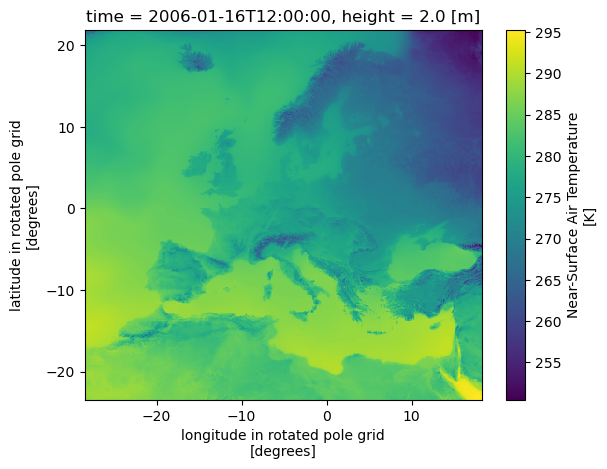

In [2]:
# Source data
ds_in = xr.open_dataset(
    "tas_EUR-11_MPI-M-MPI-ESM-LR_rcp85_r3i1p1_GERICS-REMO2015_v1_mon_200601-201012.nc"
).isel(time=0)

ds_in.tas.plot()

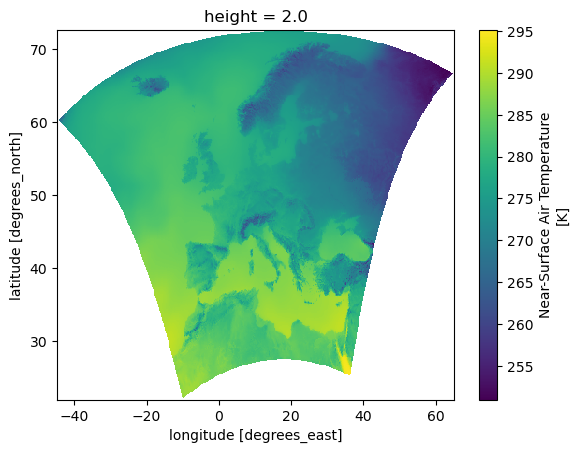

In [3]:
# Remapping & Plot
ds_out = clops.regrid(
    ds_in, grid="adaptive", method="nearest_s2d", output_type="xarray"
)[0]
ds_out.tas.plot()

## Demonstration of correct remapping of `c3s-cordex.output.ANT-44.DMI.ECMWF-ERAINT.evaluation.r1i1p1.DMI-HIRHAM5.v1.day.tas.v20201001`

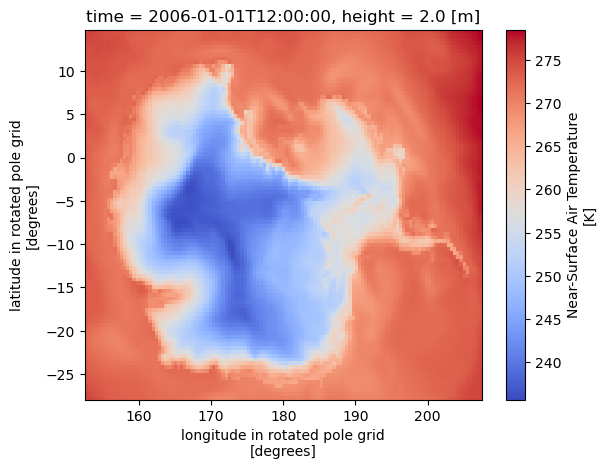

In [4]:
# Source data & Plot
ds_in = xr.open_dataset(
    "tas_ANT-44_ECMWF-ERAINT_evaluation_r1i1p1_DMI-HIRHAM5_v1_day_20060101-20101231.nc"
).isel(time=0)
ds_in.tas.plot(cmap="coolwarm")

For this dataset, the longitude coordinate is defined within the range [-165, 193] degrees, preventing an application of the remapping backend. Therefore the `clisops` library preprocesses the longitude coordinate automatically and conducts a shift for it to fit within the range [-180, 180]. In this example, values beyond 180 degrees will be subtracted by 360.

In [5]:
print(ds_in.lon.min().data, ds_in.lon.max().data)

-165.7095489501953 193.0800018310547


- Internally, when calling the regridding operator, a `Grid` object is created out of the input dataset, with all necessary preprocessing steps automatically applied:

In [6]:
grid_ds_in = clore.Grid(ds_in)
grid_ds_in

clisops 97x125_cells_grid
Lat x Lon:        97 x 125
Average resolution (x,y): (2.9030232583322833, 0.3533788522084554)
Gridcells:        12125
Format:           CF
Type:             curvilinear
Extent:           regional
Extent (x):       global
Extent (y):       regional
Source:           Dataset
Bounds?           False
Degenerate cells? None
Duplicated cells? False
Permanent Mask:   
md5 hash:         b6a79f41db4bff0553254e19581c21b2

- After the preprocessing, the minimum and maximum longitude are now within the range [-180, 180]:

In [7]:
print(grid_ds_in.ds.lon.min().data, grid_ds_in.ds.lon.max().data)

-179.977493 179.997391


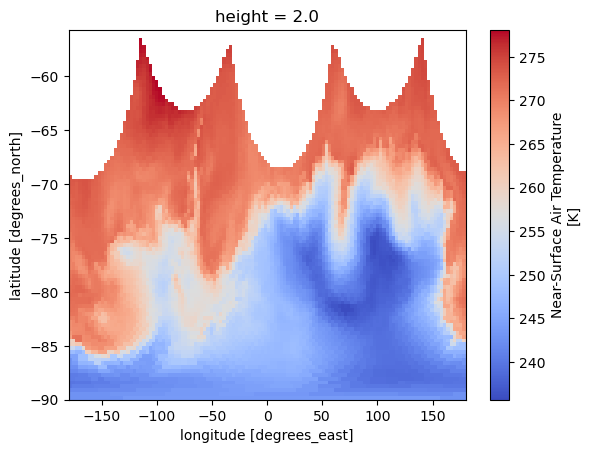

In [8]:
# Remapping & Plot
ds_out = clops.regrid(
    ds_in, grid="adaptive", method="nearest_s2d", output_type="xarray"
)[0]
ds_out.tas.plot(cmap="coolwarm")

Text(0.5, 1.0, 'TAS over Antarctica')

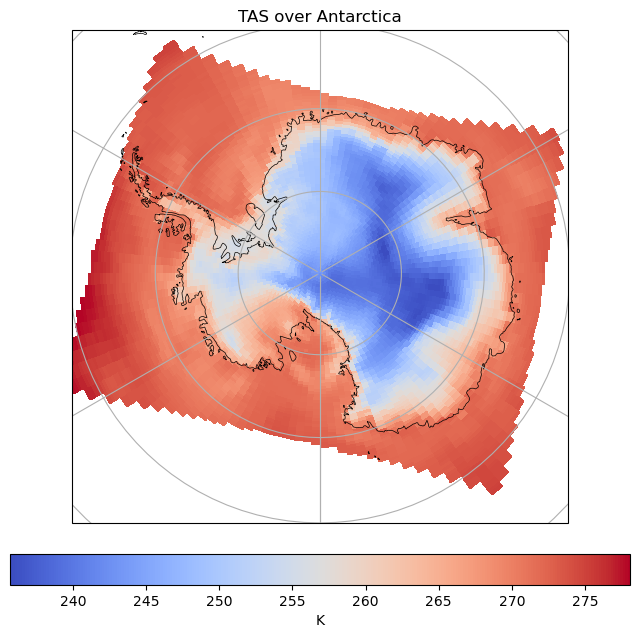

In [9]:
# Polar Stereographic Plot

fig = plt.figure(figsize=(8, 8))

# Use a South Polar Stereographic projection
proj = ccrs.SouthPolarStereo()

ax = plt.subplot(1, 1, 1, projection=proj)

# Set the map extent to show the Antarctic region
ax.set_extent([-180, 180, -90, -60], ccrs.PlateCarree())

# Add map features
ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
ax.gridlines(draw_labels=False)

# Plot the data
# transform=ccrs.PlateCarree() tells cartopy the data's coordinate system
tas_plot = ax.pcolormesh(
    ds_out.lon,
    ds_out.lat,
    ds_out.tas,
    transform=ccrs.PlateCarree(),
    cmap="coolwarm",
)

# Add colorbar
cbar = plt.colorbar(tas_plot, ax=ax, orientation="horizontal", pad=0.05)
cbar.set_label(f"{ds_out.tas.units}")

plt.title(f"TAS over Antarctica")
plt.show()

## Demonstration of correct remapping of `c3s-cordex.output.ARC-44.BCCR.ECMWF-ERAINT.evaluation.r1i1p1.BCCR-WRF331.v1.day.tas.v20200915`

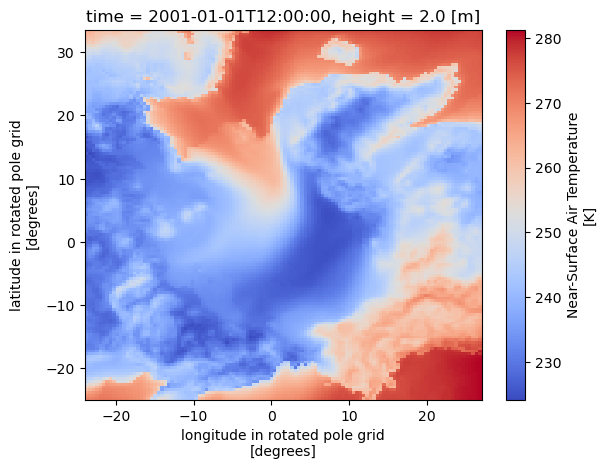

In [10]:
# Source data & Plot
ds_in = xr.open_dataset(
    "tas_ARC-44_ECMWF-ERAINT_evaluation_r1i1p1_BCCR-WRF331_v1_day_20010101-20051231.nc"
).isel(time=0)
ds_in.tas.plot(cmap="coolwarm")

The dataset has an illegal bounds definition for a curvilinear grid, only specifying 2 vertices of each (quadrilateral) cell instead of all 4. It is likely that `lon_bnds` and `lat_bnds` of the dataset are actually the bounds of the `rlon` and `rlat` coordinates of the rotated grid, incorrectly attributed / labeled as vertices of the geographic coordinates `lon` and `lat` by the data providers:

In [11]:
ds_in

<xarray.Dataset> Size: 804kB
Dimensions:       (rlon: 116, rlat: 133, bnds: 2)
Coordinates:
    time          datetime64[ns] 8B 2001-01-01T12:00:00
  * rlon          (rlon) float64 928B -23.76 -23.32 -22.88 ... 25.96 26.4 26.84
  * rlat          (rlat) float64 1kB -24.75 -24.31 -23.87 ... 32.45 32.89 33.33
    height        float64 8B ...
    lon           (rlat, rlon) float64 123kB ...
    lat           (rlat, rlon) float64 123kB ...
Dimensions without coordinates: bnds
Data variables:
    rotated_pole  |S1 1B ...
    tas           (rlat, rlon) float32 62kB ...
    time_bnds     (bnds) datetime64[ns] 16B ...
    lon_bnds      (rlat, rlon, bnds) float64 247kB ...
    lat_bnds      (rlat, rlon, bnds) float64 247kB ...
Attributes: (12/22)
    Conventions:                    CF-1.4
    contact:                        Martin King, cordex@uni.no
    comment:                        data are runs in 12-year tiling, first tw...
    experiment_id:                  evaluation
    experiment:                     Evaluation run with reanalysis forcing
    driving_experiment:             ECMWF-ERAINT,evaluation,r1i1p1
    ...                             ...
    product:                        output
    references:                     http://uni.no/en/uni-climate/
    creation_date:                  2015-06-23-T16:16:16Z
    c3s_comment:                    This data has been published at ESGF with...
    tracking_id:                    hdl:21.14103/52c38f93-1e6b-47db-b191-281c...
    c3s_disclaimer:                 This data has been curated and prepared i...

The `clisops` regrid operator automatically drops bounds with illegal shapes and optionally recomputes them when they are required, which is the case for `conservative` remapping. The bounds computation is supported for rectilinear and curvilinear grids.

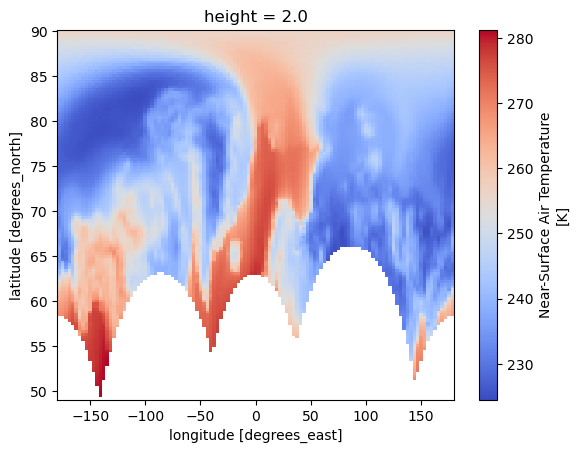

In [12]:
# Remapping & Plot
ds_out = clops.regrid(
    ds_in, grid="adaptive", method="conservative", output_type="xarray"
)[0]
ds_out.tas.plot(cmap="coolwarm")

Text(0.5, 1.0, 'TAS over the Arctic')

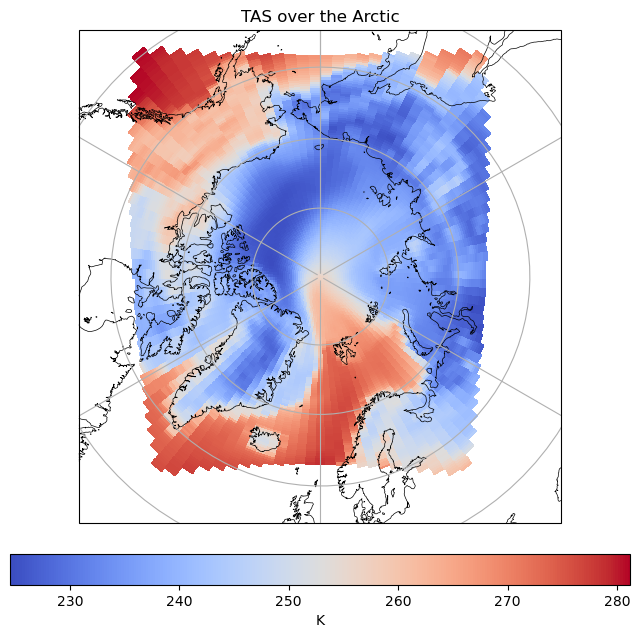

In [13]:
# Polar Stereographic Plot

fig = plt.figure(figsize=(8, 8))

# Use a North Polar Stereographic projection
proj = ccrs.NorthPolarStereo()

ax = plt.subplot(1, 1, 1, projection=proj)

# Set the map extent to show the Antarctic region
ax.set_extent([-180, 180, 90, 55], ccrs.PlateCarree())

# Add map features
ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
ax.gridlines(draw_labels=False)

# Plot the data
# transform=ccrs.PlateCarree() tells cartopy the data's coordinate system
tas_plot = ax.pcolormesh(
    ds_out.lon,
    ds_out.lat,
    ds_out.tas,
    transform=ccrs.PlateCarree(),
    cmap="coolwarm",
)

# Add colorbar
cbar = plt.colorbar(tas_plot, ax=ax, orientation="horizontal", pad=0.05)
cbar.set_label(f"{ds_out.tas.units}")

plt.title(f"TAS over the Arctic")
plt.show()